# 1. Libraries

In [12]:
import numpy as np
import scipy
import scipy.fft
import scipy.stats
import matplotlib
import matplotlib.pyplot as plt
import sympy as sp
from sympy import lambdify
from itertools import combinations
from operator import itemgetter
import time

matplotlib.rcParams['font.family']     = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['font.size']       = 12
matplotlib.rcParams['pdf.fonttype']    = 42
matplotlib.rcParams['ps.fonttype']     = 42

# 2. Functions

In [13]:
def filter_function_bi(t, t1, t2, rho):
    exp1 = 4; exp2 = 3
    norm = np.max(np.abs(
        (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) -
        (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2))
    ))
    return (
        (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) -
        (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2))
    ) / norm


def AreaTimeScaleFilter(t1, t2, rho):
    model = filter_function_bi(T_array_filter, t1, t2, rho)
    area  = np.sum(0.5*(np.roll(model,-1) + model)[:-1]*dt)
    area_abs = np.sum(0.5*(np.abs(np.roll(model,-1)) + np.abs(model))[:-1]*dt)
    area_cum = np.cumsum(0.5*(np.abs(np.roll(model,-1)) + np.abs(model))[:-1]*dt)
    idx_half = np.where(area_cum >= area_abs/2)[0][0]
    return area, T_array_filter[idx_half]


def Biphasic_Filter(Omega, TauB1, TauB2, rho):
    return (6/(1 + (1j*Omega*TauB1))**4) - ((2*rho)/(1 + (1j*Omega*TauB2))**3)

def Biphasic_FilterConjugate(Omega, TauB1, TauB2, rho):
    return (6/(1 - (1j*Omega*TauB1))**4) - ((2*rho)/(1 - (1j*Omega*TauB2))**3)

def LowPass_Filter(Omega, Tau, alpha):
    return alpha / (1 + (1j*Omega*Tau))

def LowPass_FilterConjugate(Omega, Tau, alpha):
    return alpha / (1 - (1j*Omega*Tau))

def CutOff_Filter(Omega, w0, B, n_order):
    return 1/np.sqrt(1 + ((Omega**2 - w0**2)/(B*Omega + np.spacing(1)))**(2*n_order))


def H1_sq_function(Omega):
    T1_sq = LowPass_Filter(Omega,Tau1,alpha1)*LowPass_FilterConjugate(Omega,Tau1,alpha1)
    T2_sq = LowPass_Filter(Omega,Tau2,alpha2)*LowPass_FilterConjugate(Omega,Tau2,alpha2)
    T3_sq = LowPass_Filter(Omega,Tau3,alpha3)*LowPass_FilterConjugate(Omega,Tau3,alpha3)
    T12   = LowPass_Filter(Omega,Tau1,alpha1)*LowPass_FilterConjugate(Omega,Tau2,alpha2)
    T13   = LowPass_Filter(Omega,Tau1,alpha1)*LowPass_FilterConjugate(Omega,Tau3,alpha3)
    T23   = LowPass_Filter(Omega,Tau2,alpha2)*LowPass_FilterConjugate(Omega,Tau3,alpha3)
    T21   = LowPass_Filter(Omega,Tau2,alpha2)*LowPass_FilterConjugate(Omega,Tau1,alpha1)
    T31   = LowPass_Filter(Omega,Tau3,alpha3)*LowPass_FilterConjugate(Omega,Tau1,alpha1)
    T32   = LowPass_Filter(Omega,Tau3,alpha3)*LowPass_FilterConjugate(Omega,Tau2,alpha2)
    H1_sq      = (CutOff_F**2)*(T1_sq+T2_sq+T3_sq+T12+T13+T23+T21+T31+T32)
    H1_sq_conj = (CutOff_F**2)*(T1_sq+T2_sq+T3_sq+T12+T13+T23+T21+T31+T32)
    H1_    = CutOff_F*(LowPass_Filter(Omega,Tau1,alpha1)+LowPass_Filter(Omega,Tau2,alpha2)+LowPass_Filter(Omega,Tau3,alpha3))
    H1_conj= CutOff_F*(LowPass_FilterConjugate(Omega,Tau1,alpha1)+LowPass_FilterConjugate(Omega,Tau2,alpha2)+LowPass_FilterConjugate(Omega,Tau3,alpha3))
    return H1_sq, H1_sq_conj, H1_, H1_conj


def autocorrelation_c_F(Omega, TauB1_1, TauB2_1, TauB1_2, TauB2_2, rho1, rho2, Pol1, Pol2):
    BF = Pol1*Biphasic_Filter(Omega,TauB1_1,TauB2_1,rho1)*Pol2*Biphasic_FilterConjugate(Omega,TauB1_2,TauB2_2,rho2)
    H1_H2 = BF*(2*np.real(H1_))
    return (SigmaW**2)*BF*H1_sq + (SigmaW2**2)*BF + SigmaW*SigmaW2*H1_H2

def correlation_q_F(Omega, TauB1, TauB2, rho, Pol):
    BF = Pol*Biphasic_Filter(Omega, TauB1, TauB2, rho)
    return (SigmaW**2)*BF*H1_sq + SigmaW*SigmaW2*H1_conj*BF

def correlation_q_F_conjugate(Omega, TauB1, TauB2, rho, Pol):
    BF = Pol*Biphasic_FilterConjugate(Omega, TauB1, TauB2, rho)
    return (SigmaW**2)*BF*H1_sq_conj + SigmaW*SigmaW2*H1_*BF


def Filters_analytics(N_neu):
    C  = sp.symbols('C:'+str(N_neu)+':'+str(N_neu))
    Qs = sp.symbols('Q:'+str(N_neu))
    C_mat   = np.reshape(list(C), (N_neu, N_neu))
    C_mat_T = np.transpose(C_mat)
    den = sp.Matrix(C_mat).det() + np.spacing(1)
    MF_ = np.reshape(list(Qs), (1, N_neu))
    F   = np.reshape(den, (1, 1))
    for i in range(N_neu-1):
        MF_ = np.append(MF_, np.reshape(list(Qs),(1,N_neu)), axis=0)
        F   = np.append(F, np.reshape(den,(1,1)), axis=0)
    for i1 in range(N_neu):
        C_mat_ = np.roll(C_mat_T, -i1, axis=0)
        MF_ = np.append(MF_, np.append(np.reshape(list(Qs),(1,N_neu)), C_mat_[1:,:], axis=0), axis=0)
    MF = sp.Matrix(MF_[N_neu:, :])
    F_ = ((-1)**((N_neu-1)*0))*MF[:N_neu,:].det()/den
    for i1 in range(1, N_neu):
        F_ = np.append(F_, ((-1)**((N_neu-1)*i1))*MF[i1*N_neu:i1*N_neu+N_neu,:].det()/den)
    F_ = sp.Matrix(F_)
    return lambdify([*Qs, *C], F_, 'numpy')


def Filters(Q__, G__):
    F    = F_an(*Q__[:,:], *G__[:,:])
    N_f  = N_neurons + N_neurons**2
    F_sq = np.zeros((N_f, Nt), dtype=complex)
    for i in range(N_neurons):
        F_sq[i,:] = F[i,0,:]
    ctr = N_neurons - 1
    for i in range(N_neurons):
        for j in range(N_neurons):
            ctr += 1
            F_sq[ctr,:] = np.conjugate(F_sq[i,:])*F_sq[j,:]
    return F_sq

# 3. Parameters

In [ ]:
path_to_data = "user-path-to-data"

# Stimulus model
SigmaW       = 1.0
SigmaW2      = 0.0
Sigma_Grading= 0.05
Tau1, Tau2, Tau3       = 0.01, 20.0, 0.5
alpha1, alpha2, alpha3 = 0.1,  100,  0.0
cte_MSE = 1/(2*np.pi)

# Integration grid
dt    = 0.001
T_max = 200
T_array        = np.round(np.arange(-T_max, T_max, dt), decimals=3)
T_array_filter = np.round(np.arange(0,      T_max, dt), decimals=3)
Nt     = T_array.size
dOmega = (1/dt) / Nt

# Band-pass filter
WL, WH   = 1, 100
n_order  = 4
Omega_array = 2*np.pi*scipy.fft.fftshift(scipy.fft.fftfreq(Nt, dt))
CutOff_F    = CutOff_Filter(Omega_array, np.sqrt(WH*WL), WH-WL, n_order)

# Signal power (shared across sections)
H1_sq, H1_sq_conj, H1_, H1_conj = H1_sq_function(Omega_array)
S_sq = np.trapz((SigmaW**2)*H1_sq, Omega_array)/(2*np.pi)

# Motion-pathway definitions (color matches Filter_notebook)
pathways = [
    {'name': 'Lamina',
     'neurons':    ['L1',      'L2',      'L3'     ],
     'plot_names': ['L1',      'L2',      'L3'     ],
     'color': 'olive'},
    {'name': 'ON Medulla',
     'neurons':    ['Mi1',     'Mi9',     'Tm3',     'Mi4'   ],
     'plot_names': ['Mi1',     'Mi9',     'Tm3',     'Mi4'   ],
     'color': 'yellow'},
    {'name': 'OFF Medulla',
     'neurons':    ['Tm1_OFF', 'Tm2_OFF', 'Tm4_OFF', 'Tm9_OFF'],
     'plot_names': ['Tm1',     'Tm2',     'Tm4',     'Tm9'    ],
     'color': 'darkorange'},
]

# 4. SNR — N = 2 neurons

/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_94285/4178083448.py:85: ComplexWarning: Casting complex values to real discards the imaginary part
  SNR_arr[i_comb] = S_sq / (S_sq + Int)


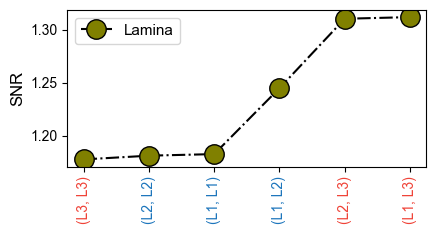

/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_94285/4178083448.py:85: ComplexWarning: Casting complex values to real discards the imaginary part
  SNR_arr[i_comb] = S_sq / (S_sq + Int)


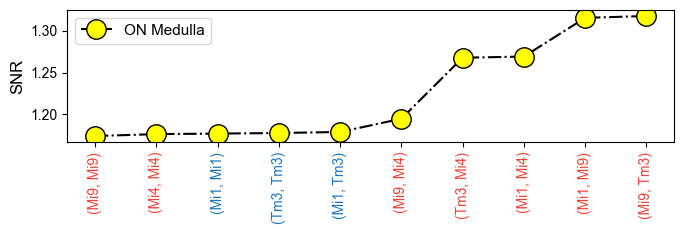

/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_94285/4178083448.py:85: ComplexWarning: Casting complex values to real discards the imaginary part
  SNR_arr[i_comb] = S_sq / (S_sq + Int)


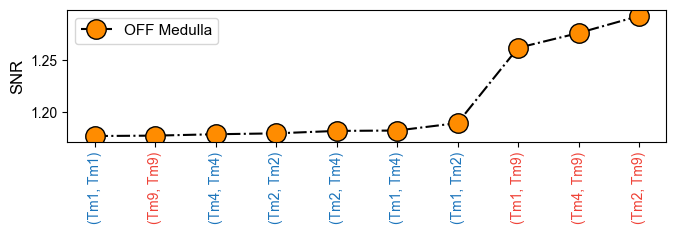

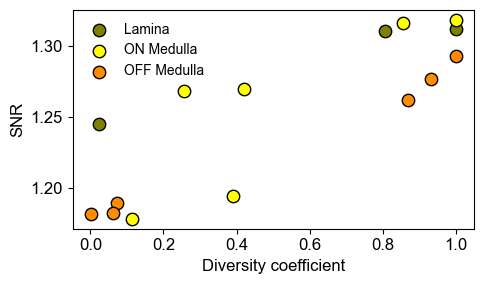

In [15]:
N_neurons = 2
F_an      = Filters_analytics(N_neurons)

monopolar_set   = {'L3', 'Mi4', 'Mi9', 'Tm9'}
color_bipolar   = '#1c75bc'
color_monopolar = '#ef4237'

diversity_n2    = {}   # for temporal diversity cell
all_div_snr_n2  = {}   # for combined scatter

for pway in pathways:
    neurons  = pway['neurons']
    p_names  = pway['plot_names']
    N_p      = len(neurons)
    color    = pway['color']
    pname    = pway['name']

    pars_arr = np.zeros((N_p, 4))
    area_arr = np.zeros(N_p)
    half_arr = np.zeros(N_p)
    F_time   = np.zeros((N_p, T_array_filter.size))
    for ii, nname in enumerate(neurons):
        pars = np.loadtxt(path_to_data + '/' + nname + '_filter_parameters_polished.txt')
        pars_arr[ii, 0] = 1
        pars_arr[ii, 1] = 1 - pars[2]
        pars_arr[ii, 2:] = pars[:2]
        F_time[ii, :] = np.abs(filter_function_bi(T_array_filter, pars_arr[ii,2], pars_arr[ii,3], pars_arr[ii,1]) + np.spacing(1))
        area_arr[ii], half_arr[ii] = AreaTimeScaleFilter(pars_arr[ii,2], pars_arr[ii,3], pars_arr[ii,1])

    test_list = list(np.repeat(np.arange(N_p)+1, N_neurons))
    comb_idx  = np.array(list(set(combinations(test_list, N_neurons)))) - 1
    N_comb    = comb_idx.shape[0]
    string_comb = []
    for ii in range(N_comb):
        getter = itemgetter(*comb_idx[ii,:])
        string_comb.append(tuple(getter(p_names)))

    Pol_par = np.zeros(N_neurons);  rho   = np.zeros(N_neurons)
    TauB1   = np.zeros(N_neurons);  TauB2 = np.zeros(N_neurons)
    CT_F_   = np.zeros((N_neurons*N_neurons, Nt), dtype=complex)
    Q       = np.zeros((N_neurons, Nt), dtype=complex)
    Q_      = np.zeros((N_neurons, Nt), dtype=complex)

    SNR_arr        = np.zeros(N_comb)
    diversity_coef = np.zeros(N_comb)
    idx_unique     = np.zeros(N_comb, dtype=int)

    for i_comb in range(N_comb):
        N_pairs = int(0.5*(N_neurons**2 - N_neurons))
        a_dif = np.zeros(N_pairs);  h_dif = np.zeros(N_pairs)
        kk = 0
        for ia in range(N_neurons):
            for ib in range(ia+1, N_neurons):
                n1, n2 = comb_idx[i_comb,ia], comb_idx[i_comb,ib]
                a_dif[kk] = area_arr[n1] - area_arr[n2]
                h_dif[kk] = half_arr[n1] - half_arr[n2]
                kk += 1
        a_dif /= 1;  h_dif /= 0.6
        diversity_coef[i_comb] = np.sum(np.unique(a_dif)**2 + np.unique(h_dif)**2)
        if np.unique(comb_idx[i_comb,:]).size == N_neurons:
            idx_unique[i_comb] = 1

        for jj in range(N_neurons):
            Pol_par[jj], rho[jj], TauB1[jj], TauB2[jj] = pars_arr[comb_idx[i_comb,jj], :]
        for jj in range(N_neurons):
            Q[jj,:]  = correlation_q_F(Omega_array, TauB1[jj], TauB2[jj], rho[jj], Pol_par[jj])
            Q_[jj,:] = correlation_q_F_conjugate(Omega_array, TauB1[jj], TauB2[jj], rho[jj], Pol_par[jj])
            for kk in range(N_neurons):
                idx_ct = jj*N_neurons + kk
                CT_F_[idx_ct,:] = autocorrelation_c_F(
                    Omega_array, TauB1[jj], TauB2[jj], TauB1[kk], TauB2[kk],
                    rho[jj], rho[kk], Pol_par[jj], Pol_par[kk])
                if jj == kk:
                    CT_F_[idx_ct,:] += Sigma_Grading**2

        h_g = np.copy(CT_F_)
        Filters_fin = Filters(Q, h_g)
        T = np.zeros(Nt, dtype=complex)
        for jj in range(N_neurons):
            T += -2*Q_[jj,:]*Filters_fin[jj,:]
            for kk in range(N_neurons):
                idx_ct = jj*N_neurons + kk
                T += np.conj(h_g[idx_ct,:])*Filters_fin[N_neurons + idx_ct,:]
        Int = np.sum(cte_MSE*T)*dOmega
        SNR_arr[i_comb] = S_sq / (S_sq + Int)

    max_div = np.max(diversity_coef)
    if max_div > 0:
        diversity_coef /= max_div

    idx_uniq = np.where(idx_unique==1)[0]
    diversity_n2[pname]   = (diversity_coef[idx_uniq], [string_comb[i] for i in idx_uniq])
    all_div_snr_n2[pname] = (diversity_coef[idx_uniq], SNR_arr[idx_uniq], color)

    # --- Plot 1: sorted SNR for ALL combinations, colored x-tick labels ---
    idx_sort_all      = np.argsort(SNR_arr)
    sorted_SNR_all    = SNR_arr[idx_sort_all]
    sorted_labels_all = [string_comb[i] for i in idx_sort_all]

    Fig, ax = plt.subplots(1, figsize=(max(3, N_comb*0.6+1), 2.5))
    ax.plot(np.arange(N_comb), sorted_SNR_all, marker='o', markerfacecolor=color,
            markeredgecolor='k', markersize=14, linestyle='-.', color='k', label=pname)
    ax.set_xticks(np.arange(N_comb))
    ax.set_xticklabels(['('+', '.join(s)+')' for s in sorted_labels_all],
                       rotation='vertical', fontsize=10)
    for tick_lbl, circuit in zip(ax.get_xticklabels(), sorted_labels_all):
        tick_lbl.set_color(color_monopolar if any(n in monopolar_set for n in circuit) else color_bipolar)
    ax.set_ylabel('SNR', fontsize=12)
    ax.legend(loc=2, fontsize=11)
    ax.tick_params(labelsize=10)
    plt.tight_layout()
    plt.show()

# --- Plot 2: combined SNR vs diversity (all pathways, unique circuits only) ---
Fig2, ax2 = plt.subplots(1, figsize=(5, 3))
for pname, (div_data, snr_data, col) in all_div_snr_n2.items():
    ax2.scatter(div_data, snr_data, c=col, edgecolors='k', s=80, zorder=3, label=pname)
ax2.set_xlabel('Diversity coefficient', fontsize=12)
ax2.set_ylabel('SNR', fontsize=12)
ax2.legend(fontsize=10, frameon=False)
ax2.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# 5. SNR — N = 3 neurons

/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_94285/4085872179.py:84: ComplexWarning: Casting complex values to real discards the imaginary part
  SNR_arr[i_comb] = S_sq / (S_sq + Int)


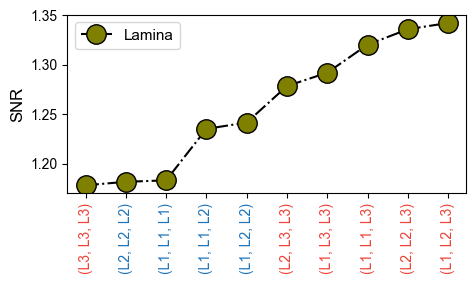

/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_94285/4085872179.py:84: ComplexWarning: Casting complex values to real discards the imaginary part
  SNR_arr[i_comb] = S_sq / (S_sq + Int)


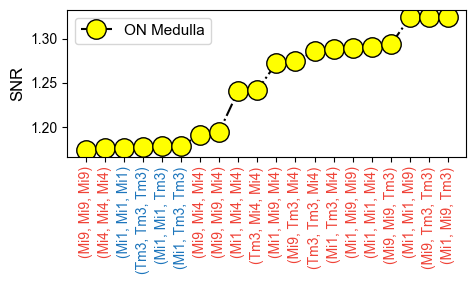

/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_94285/4085872179.py:84: ComplexWarning: Casting complex values to real discards the imaginary part
  SNR_arr[i_comb] = S_sq / (S_sq + Int)


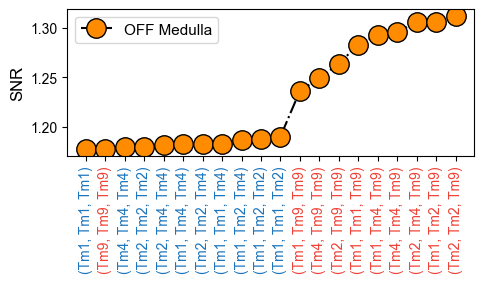

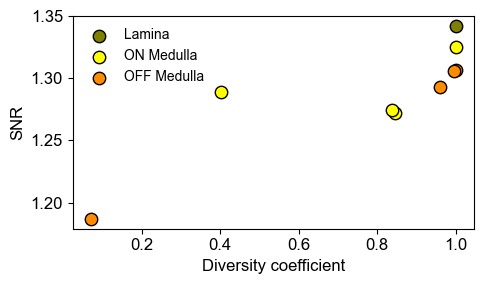

In [20]:
N_neurons = 3
F_an      = Filters_analytics(N_neurons)

monopolar_set   = {'L3', 'Mi4', 'Mi9', 'Tm9'}
color_bipolar   = '#1c75bc'
color_monopolar = '#ef4237'

all_div_snr_n3  = {}   # for combined scatter

for pway in pathways:
    neurons  = pway['neurons']
    p_names  = pway['plot_names']
    N_p      = len(neurons)
    color    = pway['color']
    pname    = pway['name']

    pars_arr = np.zeros((N_p, 4))
    area_arr = np.zeros(N_p)
    half_arr = np.zeros(N_p)
    F_time   = np.zeros((N_p, T_array_filter.size))
    for ii, nname in enumerate(neurons):
        pars = np.loadtxt(path_to_data + '/' + nname + '_filter_parameters_polished.txt')
        pars_arr[ii, 0] = 1
        pars_arr[ii, 1] = 1 - pars[2]
        pars_arr[ii, 2:] = pars[:2]
        F_time[ii, :] = np.abs(filter_function_bi(T_array_filter, pars_arr[ii,2], pars_arr[ii,3], pars_arr[ii,1]) + np.spacing(1))
        area_arr[ii], half_arr[ii] = AreaTimeScaleFilter(pars_arr[ii,2], pars_arr[ii,3], pars_arr[ii,1])

    test_list = list(np.repeat(np.arange(N_p)+1, N_neurons))
    comb_idx  = np.array(list(set(combinations(test_list, N_neurons)))) - 1
    N_comb    = comb_idx.shape[0]
    string_comb = []
    for ii in range(N_comb):
        getter = itemgetter(*comb_idx[ii,:])
        string_comb.append(tuple(getter(p_names)))

    Pol_par = np.zeros(N_neurons);  rho   = np.zeros(N_neurons)
    TauB1   = np.zeros(N_neurons);  TauB2 = np.zeros(N_neurons)
    CT_F_   = np.zeros((N_neurons*N_neurons, Nt), dtype=complex)
    Q       = np.zeros((N_neurons, Nt), dtype=complex)
    Q_      = np.zeros((N_neurons, Nt), dtype=complex)

    SNR_arr        = np.zeros(N_comb)
    diversity_coef = np.zeros(N_comb)
    idx_unique     = np.zeros(N_comb, dtype=int)

    for i_comb in range(N_comb):
        N_pairs = int(0.5*(N_neurons**2 - N_neurons))
        a_dif = np.zeros(N_pairs);  h_dif = np.zeros(N_pairs)
        kk = 0
        for ia in range(N_neurons):
            for ib in range(ia+1, N_neurons):
                n1, n2 = comb_idx[i_comb,ia], comb_idx[i_comb,ib]
                a_dif[kk] = area_arr[n1] - area_arr[n2]
                h_dif[kk] = half_arr[n1] - half_arr[n2]
                kk += 1
        a_dif /= 1;  h_dif /= 0.6
        diversity_coef[i_comb] = np.sum(np.unique(a_dif)**2 + np.unique(h_dif)**2)
        if np.unique(comb_idx[i_comb,:]).size == N_neurons:
            idx_unique[i_comb] = 1

        for jj in range(N_neurons):
            Pol_par[jj], rho[jj], TauB1[jj], TauB2[jj] = pars_arr[comb_idx[i_comb,jj], :]
        for jj in range(N_neurons):
            Q[jj,:]  = correlation_q_F(Omega_array, TauB1[jj], TauB2[jj], rho[jj], Pol_par[jj])
            Q_[jj,:] = correlation_q_F_conjugate(Omega_array, TauB1[jj], TauB2[jj], rho[jj], Pol_par[jj])
            for kk in range(N_neurons):
                idx_ct = jj*N_neurons + kk
                CT_F_[idx_ct,:] = autocorrelation_c_F(
                    Omega_array, TauB1[jj], TauB2[jj], TauB1[kk], TauB2[kk],
                    rho[jj], rho[kk], Pol_par[jj], Pol_par[kk])
                if jj == kk:
                    CT_F_[idx_ct,:] += Sigma_Grading**2

        h_g = np.copy(CT_F_)
        Filters_fin = Filters(Q, h_g)
        T = np.zeros(Nt, dtype=complex)
        for jj in range(N_neurons):
            T += -2*Q_[jj,:]*Filters_fin[jj,:]
            for kk in range(N_neurons):
                idx_ct = jj*N_neurons + kk
                T += np.conj(h_g[idx_ct,:])*Filters_fin[N_neurons + idx_ct,:]
        Int = np.sum(cte_MSE*T)*dOmega
        SNR_arr[i_comb] = S_sq / (S_sq + Int)

    max_div = np.max(diversity_coef)
    if max_div > 0:
        diversity_coef /= max_div

    idx_uniq = np.where(idx_unique==1)[0]
    all_div_snr_n3[pname] = (diversity_coef[idx_uniq], SNR_arr[idx_uniq], color)

    # --- Plot 1: sorted SNR for ALL combinations, colored x-tick labels ---
    idx_sort_all      = np.argsort(SNR_arr)
    sorted_SNR_all    = SNR_arr[idx_sort_all]
    sorted_labels_all = [string_comb[i] for i in idx_sort_all]

    #Fig, ax = plt.subplots(1, figsize=(max(3, N_comb*0.6+1), 2.5))
    Fig, ax = plt.subplots(1, figsize=(5, 3))
    ax.plot(np.arange(N_comb), sorted_SNR_all, marker='o', markerfacecolor=color,
            markeredgecolor='k', markersize=14, linestyle='-.', color='k', label=pname)
    ax.set_xticks(np.arange(N_comb))
    ax.set_xticklabels(['('+', '.join(s)+')' for s in sorted_labels_all],
                       rotation='vertical', fontsize=10)
    for tick_lbl, circuit in zip(ax.get_xticklabels(), sorted_labels_all):
        tick_lbl.set_color(color_monopolar if any(n in monopolar_set for n in circuit) else color_bipolar)
    ax.set_ylabel('SNR', fontsize=12)
    ax.legend(loc=2, fontsize=11)
    ax.tick_params(labelsize=10)
    plt.tight_layout()
    plt.savefig("SNR_CircuitLabels_triplets_"+str(pname)+".pdf", dpi = 300, bbox_inches = 'tight')
    plt.show()

# --- Plot 2: combined SNR vs diversity (all pathways, unique circuits only) ---
Fig2, ax2 = plt.subplots(1, figsize=(5, 3))
for pname, (div_data, snr_data, col) in all_div_snr_n3.items():
    ax2.scatter(div_data, snr_data, c=col, edgecolors='k', s=80, zorder=3, label=pname)
ax2.set_xlabel('Diversity coefficient', fontsize=12)
ax2.set_ylabel('SNR', fontsize=12)
ax2.legend(fontsize=10, frameon=False)
ax2.tick_params(labelsize=12)
plt.tight_layout()
plt.savefig("SNR_DivCoeff_triplets.pdf", dpi = 300, bbox_inches = 'tight')
plt.show()

# 6. Temporal diversity (N = 2)

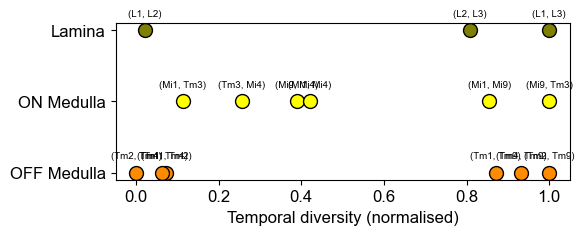

In [18]:
y_levels   = {'Lamina': 2, 'ON Medulla': 1, 'OFF Medulla': 0}
colors_div = {'Lamina': 'olive', 'ON Medulla': 'yellow', 'OFF Medulla': 'darkorange'}
y_ticklabels = ['OFF Medulla', 'ON Medulla', 'Lamina']

Fig, ax = plt.subplots(1, figsize=(6, 2.5))

for pway in pathways:
    pname = pway['name']
    if pname not in diversity_n2:
        continue
    div_coefs, labels = diversity_n2[pname]
    y = y_levels[pname]
    c = colors_div[pname]
    ax.plot(div_coefs, y*np.ones(div_coefs.size), marker='o', linestyle='none',
            markeredgecolor='k', markerfacecolor=c, markersize=10, label=pname)
    for xi, lab in zip(div_coefs, labels):
        ax.annotate('('+', '.join(lab)+')', (xi, y),
                    fontsize=7, textcoords='offset points', xytext=(0, 10), ha='center')

ax.set_yticks([0, 1, 2])
ax.set_yticklabels(y_ticklabels, fontsize=10)
ax.set_xlabel('Temporal diversity (normalised)', fontsize=12)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.savefig('TemporalDiversity_motionpathway.pdf', bbox_inches='tight', dpi=300)
plt.show()

# 7. Sensitivity analysis with power-law slope

In [ ]:
tau2_values = np.arange(5, 61, 5)

# ── Compute power-law exponent k for each Tau2 (analytical, no random noise) ──
# Replicates the log-log slope fit from Stimulus_notebook using the expected
# power spectrum  |BandPass(f) × (LP1(f) + LP2(f) + LP3(f))|²

_T_stim  = 300.0;  _dt_stim = 0.001
_n_stim  = int(2 * _T_stim / _dt_stim)
_Freq    = scipy.fft.fftshift(scipy.fft.fftfreq(n=_n_stim, d=_dt_stim))

_WL, _WH = 1.0, 100.0
_B, _w0  = _WH - _WL, np.sqrt(_WH * _WL)
_n_ord   = 4

# Band-pass filter (identical parameterisation to LaminaMedulla)
_BP = 1 / np.sqrt(1 + ((_Freq**2 - _w0**2) / (_B * _Freq + np.spacing(1)))**(2*_n_ord))

# Low-pass helpers using regular frequency (as in Stimulus_notebook)
def _LP(f, amp, tau): return amp / (1 + 1j * f * tau)

_idx_min = np.where(_Freq > _WL)[0][0]
_idx_max = np.where(_Freq > _WH)[0][0]

k_values = np.zeros(len(tau2_values))
for _i, _t2 in enumerate(tau2_values):
    _H   = _BP * (_LP(_Freq, alpha1, Tau1) + _LP(_Freq, alpha2, _t2) + _LP(_Freq, alpha3, Tau3))
    _PS  = np.abs(_H)**2
    k_values[_i] = np.real(np.polyfit(
        np.log(_Freq[_idx_min:_idx_max] + np.spacing(1)),
        np.log(_PS[_idx_min:_idx_max]   + np.spacing(1)), 1)[0])

print('tau2 →  k')
for t2, k in zip(tau2_values, k_values):
    print(f'  {t2:5.1f}  →  {k:.3f}')

# ── SNR vs diversity loop over Tau2 ──────────────────────────────────────────
slopes_all = []
corr_all   = []

N_neurons = 2
F_an      = Filters_analytics(N_neurons)

Tau2_orig                                            = Tau2
H1_sq_orig, H1_sq_conj_orig, H1_orig, H1_conj_orig = H1_sq, H1_sq_conj, H1_, H1_conj
S_sq_orig                                            = S_sq

for tau2_val in tau2_values:
    Tau2 = tau2_val
    H1_sq, H1_sq_conj, H1_, H1_conj = H1_sq_function(Omega_array)
    S_sq = np.trapz((SigmaW**2)*H1_sq, Omega_array) / (2*np.pi)

    div_pool = []
    snr_pool = []

    for pway in pathways:
        neurons = pway['neurons']
        N_p     = len(neurons)

        pars_arr = np.zeros((N_p, 4))
        area_arr = np.zeros(N_p)
        half_arr = np.zeros(N_p)
        for ii, nname in enumerate(neurons):
            pars             = np.loadtxt(path_to_data + '/' + nname + '_filter_parameters_polished.txt')
            pars_arr[ii, 0]  = 1
            pars_arr[ii, 1]  = 1 - pars[2]
            pars_arr[ii, 2:] = pars[:2]
            area_arr[ii], half_arr[ii] = AreaTimeScaleFilter(pars_arr[ii,2], pars_arr[ii,3], pars_arr[ii,1])

        test_list = list(np.repeat(np.arange(N_p)+1, N_neurons))
        comb_idx  = np.array(list(set(combinations(test_list, N_neurons)))) - 1
        N_comb    = comb_idx.shape[0]

        Pol_par = np.zeros(N_neurons);  rho   = np.zeros(N_neurons)
        TauB1   = np.zeros(N_neurons);  TauB2 = np.zeros(N_neurons)
        CT_F_   = np.zeros((N_neurons*N_neurons, Nt), dtype=complex)
        Q       = np.zeros((N_neurons, Nt), dtype=complex)
        Q_      = np.zeros((N_neurons, Nt), dtype=complex)

        SNR_arr        = np.zeros(N_comb)
        diversity_coef = np.zeros(N_comb)
        idx_unique     = np.zeros(N_comb, dtype=int)

        for i_comb in range(N_comb):
            N_pairs = int(0.5*(N_neurons**2 - N_neurons))
            a_dif = np.zeros(N_pairs);  h_dif = np.zeros(N_pairs)
            kk = 0
            for ia in range(N_neurons):
                for ib in range(ia+1, N_neurons):
                    n1, n2    = comb_idx[i_comb, ia], comb_idx[i_comb, ib]
                    a_dif[kk] = area_arr[n1] - area_arr[n2]
                    h_dif[kk] = half_arr[n1] - half_arr[n2]
                    kk += 1
            a_dif /= 1;  h_dif /= 0.6
            diversity_coef[i_comb] = np.sum(np.unique(a_dif)**2 + np.unique(h_dif)**2)
            if np.unique(comb_idx[i_comb,:]).size == N_neurons:
                idx_unique[i_comb] = 1

            for jj in range(N_neurons):
                Pol_par[jj], rho[jj], TauB1[jj], TauB2[jj] = pars_arr[comb_idx[i_comb, jj], :]
            for jj in range(N_neurons):
                Q[jj,:]  = correlation_q_F(Omega_array, TauB1[jj], TauB2[jj], rho[jj], Pol_par[jj])
                Q_[jj,:] = correlation_q_F_conjugate(Omega_array, TauB1[jj], TauB2[jj], rho[jj], Pol_par[jj])
                for kk in range(N_neurons):
                    idx_ct = jj*N_neurons + kk
                    CT_F_[idx_ct,:] = autocorrelation_c_F(
                        Omega_array, TauB1[jj], TauB2[jj], TauB1[kk], TauB2[kk],
                        rho[jj], rho[kk], Pol_par[jj], Pol_par[kk])
                    if jj == kk:
                        CT_F_[idx_ct,:] += Sigma_Grading**2

            h_g         = np.copy(CT_F_)
            Filters_fin = Filters(Q, h_g)
            T = np.zeros(Nt, dtype=complex)
            for jj in range(N_neurons):
                T += -2*Q_[jj,:]*Filters_fin[jj,:]
                for kk in range(N_neurons):
                    idx_ct = jj*N_neurons + kk
                    T += np.conj(h_g[idx_ct,:])*Filters_fin[N_neurons + idx_ct,:]
            Int = np.sum(cte_MSE*T)*dOmega
            SNR_arr[i_comb] = S_sq / (S_sq + Int)

        max_div = np.max(diversity_coef)
        if max_div > 0:
            diversity_coef /= max_div

        idx_uniq = np.where(idx_unique == 1)[0]
        div_pool.append(diversity_coef[idx_uniq])
        snr_pool.append(SNR_arr[idx_uniq])

    div_all = np.concatenate(div_pool)
    snr_all = np.concatenate(snr_pool)

    slope, _ = np.polyfit(div_all, snr_all, 1)
    r, _     = scipy.stats.pearsonr(div_all, snr_all)
    slopes_all.append(slope)
    corr_all.append(r)

# Restore original globals
Tau2                              = Tau2_orig
H1_sq, H1_sq_conj, H1_, H1_conj = H1_sq_orig, H1_sq_conj_orig, H1_orig, H1_conj_orig
S_sq                              = S_sq_orig

# ── Plot 1: slope vs power-law exponent k ─────────────────────────────────────
Fig, ax = plt.subplots(1, figsize=(5, 3))
ax.plot(k_values, slopes_all, marker='o', markerfacecolor='white',
        markeredgecolor='k', markersize=14, linestyle='-.', color='k')
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel('Power-law exponent  $k$', fontsize=12)
ax.set_ylabel('Slope  (SNR vs diversity)', fontsize=12)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.savefig('SensitivitySlope_vs_k.pdf', dpi=300, bbox_inches='tight')
plt.show()

# ── Plot 2: Pearson r vs power-law exponent k ─────────────────────────────────
Fig, ax = plt.subplots(1, figsize=(5, 3))
ax.plot(k_values, corr_all, marker='o', markerfacecolor='white',
        markeredgecolor='k', markersize=14, linestyle='-.', color='k')
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel('Power-law exponent  $k$', fontsize=12)
ax.set_ylabel('Pearson $r$  (SNR vs diversity)', fontsize=12)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.savefig('SensitivityCorr_vs_k.pdf', dpi=300, bbox_inches='tight')
plt.show()

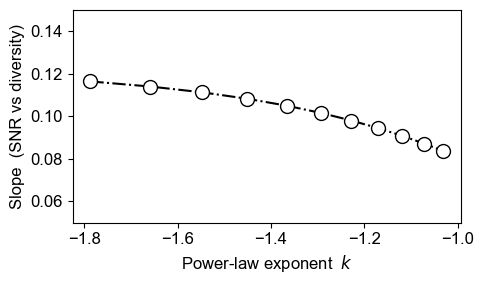

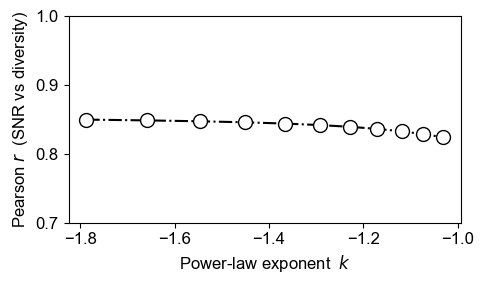

In [33]:
# ── Plot 1: slope vs power-law exponent k ─────────────────────────────────────
Fig, ax = plt.subplots(1, figsize=(5, 3))
ax.plot(k_values, slopes_all, marker='o', markerfacecolor='white',
        markeredgecolor='k', markersize=10, linestyle='-.', color='k')
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel('Power-law exponent  $k$', fontsize=12)
ax.set_ylabel('Slope  (SNR vs diversity)', fontsize=12)
ax.tick_params(labelsize=12)
ax.set_ylim(0.7, 1)
ax.set_ylim(0.05, 0.15)
plt.tight_layout()
#plt.savefig('SensitivitySlope_vs_k.pdf', dpi=300, bbox_inches='tight')
plt.show()

# ── Plot 2: Pearson r vs power-law exponent k ─────────────────────────────────
Fig, ax = plt.subplots(1, figsize=(5, 3))
ax.plot(k_values, corr_all, marker='o', markerfacecolor='white',
        markeredgecolor='k', markersize=10, linestyle='-.', color='k')
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel('Power-law exponent  $k$', fontsize=12)
ax.set_ylabel('Pearson $r$  (SNR vs diversity)', fontsize=12)
ax.tick_params(labelsize=12)
ax.set_ylim(0.7, 1)
plt.tight_layout()
#plt.savefig('SensitivityCorr_vs_k.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ── SNR vs diversity for Tau2 = 50, with linear fit ──────────────────────────
Tau2_snap = 50.0

Tau2_orig                                            = Tau2
H1_sq_orig, H1_sq_conj_orig, H1_orig, H1_conj_orig = H1_sq, H1_sq_conj, H1_, H1_conj
S_sq_orig                                            = S_sq

Tau2 = Tau2_snap
H1_sq, H1_sq_conj, H1_, H1_conj = H1_sq_function(Omega_array)
S_sq = np.trapz((SigmaW**2)*H1_sq, Omega_array) / (2*np.pi)

N_neurons = 2
F_an      = Filters_analytics(N_neurons)

all_div_snr_snap = {}   # {pname: (div_uniq, snr_uniq, color)}

for pway in pathways:
    neurons = pway['neurons']
    p_names = pway['plot_names']
    N_p     = len(neurons)
    color   = pway['color']
    pname   = pway['name']

    pars_arr = np.zeros((N_p, 4))
    area_arr = np.zeros(N_p)
    half_arr = np.zeros(N_p)
    for ii, nname in enumerate(neurons):
        pars             = np.loadtxt(path_to_data + '/' + nname + '_filter_parameters_polished.txt')
        pars_arr[ii, 0]  = 1
        pars_arr[ii, 1]  = 1 - pars[2]
        pars_arr[ii, 2:] = pars[:2]
        area_arr[ii], half_arr[ii] = AreaTimeScaleFilter(pars_arr[ii,2], pars_arr[ii,3], pars_arr[ii,1])

    test_list = list(np.repeat(np.arange(N_p)+1, N_neurons))
    comb_idx  = np.array(list(set(combinations(test_list, N_neurons)))) - 1
    N_comb    = comb_idx.shape[0]

    Pol_par = np.zeros(N_neurons);  rho   = np.zeros(N_neurons)
    TauB1   = np.zeros(N_neurons);  TauB2 = np.zeros(N_neurons)
    CT_F_   = np.zeros((N_neurons*N_neurons, Nt), dtype=complex)
    Q       = np.zeros((N_neurons, Nt), dtype=complex)
    Q_      = np.zeros((N_neurons, Nt), dtype=complex)

    SNR_arr        = np.zeros(N_comb)
    diversity_coef = np.zeros(N_comb)
    idx_unique     = np.zeros(N_comb, dtype=int)

    for i_comb in range(N_comb):
        N_pairs = int(0.5*(N_neurons**2 - N_neurons))
        a_dif = np.zeros(N_pairs);  h_dif = np.zeros(N_pairs)
        kk = 0
        for ia in range(N_neurons):
            for ib in range(ia+1, N_neurons):
                n1, n2    = comb_idx[i_comb, ia], comb_idx[i_comb, ib]
                a_dif[kk] = area_arr[n1] - area_arr[n2]
                h_dif[kk] = half_arr[n1] - half_arr[n2]
                kk += 1
        a_dif /= 1;  h_dif /= 0.6
        diversity_coef[i_comb] = np.sum(np.unique(a_dif)**2 + np.unique(h_dif)**2)
        if np.unique(comb_idx[i_comb,:]).size == N_neurons:
            idx_unique[i_comb] = 1

        for jj in range(N_neurons):
            Pol_par[jj], rho[jj], TauB1[jj], TauB2[jj] = pars_arr[comb_idx[i_comb, jj], :]
        for jj in range(N_neurons):
            Q[jj,:]  = correlation_q_F(Omega_array, TauB1[jj], TauB2[jj], rho[jj], Pol_par[jj])
            Q_[jj,:] = correlation_q_F_conjugate(Omega_array, TauB1[jj], TauB2[jj], rho[jj], Pol_par[jj])
            for kk in range(N_neurons):
                idx_ct = jj*N_neurons + kk
                CT_F_[idx_ct,:] = autocorrelation_c_F(
                    Omega_array, TauB1[jj], TauB2[jj], TauB1[kk], TauB2[kk],
                    rho[jj], rho[kk], Pol_par[jj], Pol_par[kk])
                if jj == kk:
                    CT_F_[idx_ct,:] += Sigma_Grading**2

        h_g         = np.copy(CT_F_)
        Filters_fin = Filters(Q, h_g)
        T = np.zeros(Nt, dtype=complex)
        for jj in range(N_neurons):
            T += -2*Q_[jj,:]*Filters_fin[jj,:]
            for kk in range(N_neurons):
                idx_ct = jj*N_neurons + kk
                T += np.conj(h_g[idx_ct,:])*Filters_fin[N_neurons + idx_ct,:]
        Int = np.sum(cte_MSE*T)*dOmega
        SNR_arr[i_comb] = S_sq / (S_sq + Int)

    max_div = np.max(diversity_coef)
    if max_div > 0:
        diversity_coef /= max_div

    idx_uniq = np.where(idx_unique == 1)[0]
    all_div_snr_snap[pname] = (diversity_coef[idx_uniq], SNR_arr[idx_uniq], color)

# Restore original globals
Tau2                              = Tau2_orig
H1_sq, H1_sq_conj, H1_, H1_conj = H1_sq_orig, H1_sq_conj_orig, H1_orig, H1_conj_orig
S_sq                              = S_sq_orig

# Linear fit over all pooled data
_div_all = np.concatenate([d for d, _, _ in all_div_snr_snap.values()])
_snr_all = np.concatenate([s for _, s, _ in all_div_snr_snap.values()])
_slope, _intercept = np.polyfit(_div_all, _snr_all, 1)
_x_fit = np.linspace(_div_all.min(), _div_all.max(), 200)

Fig2, ax2 = plt.subplots(1, figsize=(5, 3))
for pname, (div_data, snr_data, col) in all_div_snr_snap.items():
    ax2.scatter(div_data, snr_data, c=col, edgecolors='k', s=80, zorder=3, label=pname)
ax2.plot(_x_fit, _slope*_x_fit + _intercept, color='k', linewidth=1.2, linestyle='--', zorder=2)
ax2.set_xlabel('Diversity coefficient', fontsize=12)
ax2.set_ylabel('SNR', fontsize=12)
ax2.legend(fontsize=10, frameon=False)
ax2.tick_params(labelsize=12)
plt.tight_layout()
plt.savefig('SNR_DivCoeff_tau2_50.pdf', dpi=300, bbox_inches='tight')
plt.show()